<a href="https://colab.research.google.com/github/navyashreenavy/Airlines-Management/blob/main/Deep_learning_model_tunel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AUTOMATED HYPERPARAMETER TUNING SYSTEM
--------------------------------------
Dataset Loaded Successfully
Dataset Shape: (1797, 64)
Number of Classes: 10
Training Data: (1149, 64)
Validation Data: (288, 64)
Testing Data: (360, 64)

Starting Hyperparameter Tuning...

Trial: 1
Parameters: {'units': 32, 'hidden_layers': 1, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 8, 'optimizer': 'adam'}
Validation Accuracy: 0.9236111044883728
Validation Loss: 0.3548815846443176

Trial: 2
Parameters: {'units': 32, 'hidden_layers': 2, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 8, 'optimizer': 'adam'}
Validation Accuracy: 0.9513888955116272
Validation Loss: 0.2813045084476471

Trial: 3
Parameters: {'units': 32, 'hidden_layers': 1, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 64, 'epochs': 8, 'optimizer': 'adam'}
Validation Accuracy: 0.8854166865348816
Validation Loss: 0.6748760938644409

Trial: 4
Parameters: {'units': 32, 'hidden_layers': 2, 'dropo

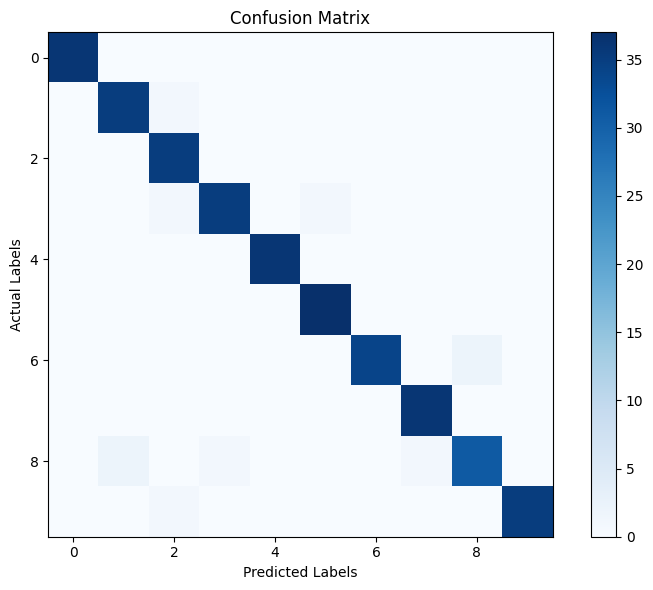

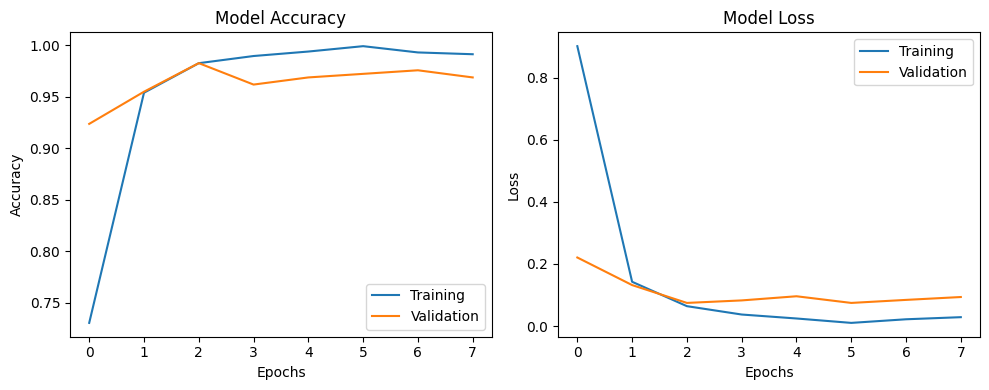


--------------------------------------
HYPERPARAMETER TUNING COMPLETED
--------------------------------------
   Trial  Accuracy      Loss  units  hidden_layers  dropout  learning_rate  \
0      1  0.923611  0.354882     32              1      0.2          0.001   
1      2  0.951389  0.281305     32              2      0.0          0.001   
2      3  0.885417  0.674876     32              1      0.2          0.001   
3      4  0.965278  0.310396     32              2      0.2          0.010   
4      5  0.854167  0.716464     32              1      0.2          0.001   
5      6  0.968750  0.093601     32              2      0.0          0.010   

   batch_size  epochs optimizer  
0          32       8      adam  
1          32       8      adam  
2          64       8      adam  
3          32       8      adam  
4          64       8      adam  
5          32       8      adam  


In [1]:
# AUTOMATED HYPERPARAMETER TUNING FOR DEEP LEARNING MODELS

# 1. Import Libraries
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import itertools
import json
import os

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

# 2. Configuration
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

OUTPUT_DIR = "tuning_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEARCH_STRATEGY = "random"  # Use "grid" or "random"
N_RANDOM_TRIALS = 6

# 3. Dataset Loading Utility
def load_dataset():
    dataset = load_digits()
    X = dataset.data.astype("float32")
    y = dataset.target

    print("Dataset Loaded Successfully")
    print("Dataset Shape:", X.shape)
    print("Number of Classes:", len(np.unique(y)))

    return X, y

# 4. Data Preprocessing
def prepare_data(X, y):

    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_full, y_train_full,
        test_size=0.2, random_state=42,
        stratify=y_train_full
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_val = scaler.transform(X_val)
    X_test = scaler.transform(X_test)

    print("Training Data:", X_train.shape)
    print("Validation Data:", X_val.shape)
    print("Testing Data:", X_test.shape)

    return X_train, X_val, X_test, y_train, y_val, y_test

# 5. Model Definition Interface
def build_model(input_dim, num_classes, params):

    model = tf.keras.Sequential()

    model.add(tf.keras.layers.Input(shape=(input_dim,)))

    for _ in range(params["hidden_layers"]):

        model.add(tf.keras.layers.Dense(
            params["units"], activation="relu"
        ))

        if params["dropout"] > 0:
            model.add(tf.keras.layers.Dropout(params["dropout"]))

    model.add(tf.keras.layers.Dense(
        num_classes, activation="softmax"
    ))

    if params["optimizer"] == "adam":
        optimizer = tf.keras.optimizers.Adam(
            learning_rate=params["learning_rate"]
        )
    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=params["learning_rate"]
        )

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# 6. Hyperparameter Search Space
search_space = {
    "units": [32, 64],
    "hidden_layers": [1, 2],
    "dropout": [0.0, 0.2],
    "learning_rate": [0.001, 0.01],
    "batch_size": [32, 64],
    "epochs": [8],
    "optimizer": ["adam"]
}

# 7. Grid Search
def grid_search(space):

    keys = list(space.keys())

    combinations = itertools.product(
        *[space[key] for key in keys]
    )

    return [
        dict(zip(keys, values))
        for values in combinations
    ]

# 8. Random Search
def random_search(space, trials):

    combinations = []

    for _ in range(trials):
        params = {
            key: random.choice(values)
            for key, values in space.items()
        }
        combinations.append(params)

    return combinations

# 9. Model Training and Evaluation
def train_model(params, X_train, y_train, X_val, y_val):

    tf.keras.backend.clear_session()

    model = build_model(
        X_train.shape[1],
        len(np.unique(y_train)),
        params
    )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=params["epochs"],
        batch_size=params["batch_size"],
        verbose=0
    )

    loss, accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    return model, history, accuracy, loss

# 10. Tuning Engine
def tuning_engine(X_train, y_train, X_val, y_val):

    if SEARCH_STRATEGY == "grid":
        combinations = grid_search(search_space)
    else:
        combinations = random_search(
            search_space, N_RANDOM_TRIALS
        )

    results = []
    best_accuracy = 0
    best_params = None
    best_history = None

    print("\nStarting Hyperparameter Tuning...")

    for i, params in enumerate(combinations):

        print("\nTrial:", i + 1)
        print("Parameters:", params)

        model, history, accuracy, loss = train_model(
            params, X_train, y_train, X_val, y_val
        )

        print("Validation Accuracy:", accuracy)
        print("Validation Loss:", loss)

        results.append({
            "Trial": i + 1,
            "Accuracy": accuracy,
            "Loss": loss,
            **params
        })

        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_params = params
            best_history = history

    results_df = pd.DataFrame(results)

    results_df.to_csv(
        OUTPUT_DIR + "/tuning_results.csv",
        index=False
    )

    print("\nBest Hyperparameters:")
    print(best_params)

    print("Best Validation Accuracy:", best_accuracy)

    return best_params, best_history, results_df

# 11. Final Model Training
def final_training(best_params, X_train, y_train, X_val, y_val):

    tf.keras.backend.clear_session()

    model = build_model(
        X_train.shape[1],
        len(np.unique(y_train)),
        best_params
    )

    X_combined = np.concatenate([X_train, X_val])
    y_combined = np.concatenate([y_train, y_val])

    model.fit(
        X_combined,
        y_combined,
        epochs=best_params["epochs"],
        batch_size=best_params["batch_size"],
        verbose=1
    )

    model.save(OUTPUT_DIR + "/best_model.keras")

    print("Best Model Saved Successfully")

    return model

# 12. Performance Evaluation
def performance_evaluation(model, X_test, y_test):

    loss, accuracy = model.evaluate(
        X_test, y_test, verbose=0
    )

    predictions = np.argmax(
        model.predict(X_test, verbose=0), axis=1
    )

    print("\nFinal Test Accuracy:", accuracy)
    print("Final Test Loss:", loss)

    print("\nClassification Report:")
    print(classification_report(
        y_test, predictions, zero_division=0
    ))

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(8, 6))
    plt.imshow(cm, cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Labels")
    plt.ylabel("Actual Labels")
    plt.colorbar()
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR + "/confusion_matrix.png")
    plt.show()

    return accuracy, loss

# 13. Training Performance Graph
def plot_training(history):

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training")
    plt.plot(history.history["val_accuracy"], label="Validation")
    plt.title("Model Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.title("Model Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR + "/training_history.png")
    plt.show()

# 14. Main Program
def main():

    print("AUTOMATED HYPERPARAMETER TUNING SYSTEM")
    print("--------------------------------------")

    # Load Dataset
    X, y = load_dataset()

    # Preprocess Dataset
    X_train, X_val, X_test, y_train, y_val, y_test = prepare_data(X, y)

    # Hyperparameter Tuning
    best_params, history, results = tuning_engine(
        X_train, y_train, X_val, y_val
    )

    # Final Model Training
    model = final_training(
        best_params, X_train, y_train, X_val, y_val
    )

    # Performance Evaluation
    accuracy, loss = performance_evaluation(
        model, X_test, y_test
    )

    # Display Graphs
    plot_training(history)

    # Save Best Hyperparameters
    output = {
        "Best Hyperparameters": best_params,
        "Test Accuracy": float(accuracy),
        "Test Loss": float(loss)
    }

    with open(
        OUTPUT_DIR + "/best_hyperparameters.json", "w"
    ) as file:
        json.dump(output, file, indent=4)

    print("\n--------------------------------------")
    print("HYPERPARAMETER TUNING COMPLETED")
    print("--------------------------------------")
    print(results)

# 15. Execute Project
if __name__ == "__main__":
    main()